# Week 13: Data Visualization – University Admissions Analysis
**Course:** DSCI 505 – Fundamental of Data Analytics
**Author:** Prakash Gautam

## Business Scenario
A university received **17,339 applications** across three colleges: Business & Economics, Math & Science, and Arts & Letters.
The admissions office wants to understand differences in application volume, academic performance, and admission outcomes across colleges.
As a Business Data Analyst, I analyze the data, find patterns, and recommend strategies for admission and enrollment planning.

## Tasks
1. **Bar Plot:** Applications by college (Matplotlib, Seaborn, Plotly)
2. **Histogram:** Distribution of SAT_ACT scores (Matplotlib, Seaborn, Plotly)
3. **Scatter Plot + Trendline:** SAT_ACT vs Extracurricular_Hours (Matplotlib, Seaborn, Plotly)
4. **Data-Driven Insights:** Three findings and recommendations

## Step 1: Import Libraries

In [26]:
# Load the tools we need for this analysis
import pandas as pd               # pandas: to read and organize the data table
import numpy as np                # numpy: for number calculations (used for the trendline)
import matplotlib.pyplot as plt   # matplotlib: basic charts
import seaborn as sns             # seaborn: nicer-looking charts with less code
import plotly.express as px       # plotly: interactive charts you can hover over and zoom

## Step 2: Load and Explore the Data

In [27]:
# Read the Excel file into a table called df (short for DataFrame)
df = pd.read_excel('applications.xlsx')
# Show the first 5 rows so we can see what the data looks like
df.head()

,Applicant,Sex,SAT_ACT,College,Admitted,Enrolled,Extracurricular_Hours
0,1,M,1460,Business & Economics,Yes,No,5
1,2,F,1180,Math & Science,No,No,10
2,3,M,1340,Arts & Letters,Yes,No,7
3,4,M,1190,Business & Economics,No,No,1
4,5,F,1290,Business & Economics,No,No,4


In [28]:
# How many rows (applicants) and columns the data has
print('Shape:', df.shape)
print("-----------------------------------")
# The names of the columns, and the type of data in each one (text, number, etc.)
print('Columns:', df.columns)
print("-----------------------------------")
print(df.dtypes)

Shape: (17339, 7)
-----------------------------------
Columns: Index(['Applicant', 'Sex', 'SAT_ACT', 'College', 'Admitted', 'Enrolled',
       'Extracurricular_Hours'],
      dtype='str')
-----------------------------------
Applicant                int64
Sex                        str
SAT_ACT                  int64
College                    str
Admitted                   str
Enrolled                   str
Extracurricular_Hours    int64
dtype: object


In [7]:
# The names of the columns, and the type of data in each one (text, number, etc.)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17339 entries, 0 to 17338
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Applicant              17339 non-null  int64
 1   Sex                    17339 non-null  str  
 2   SAT_ACT                17339 non-null  int64
 3   College                17339 non-null  str  
 4   Admitted               17339 non-null  str  
 5   Enrolled               17339 non-null  str  
 6   Extracurricular_Hours  17339 non-null  int64
dtypes: int64(3), str(4)
memory usage: 1.3 MB


## Step 3: Check for Missing Values

In [29]:
# Count how many blank (missing) values are in each column
df.isnull().sum()

Applicant                0
Sex                      0
SAT_ACT                  0
College                  0
Admitted                 0
Enrolled                 0
Extracurricular_Hours    0
dtype: int64

In [30]:
# If any rows have blank values, remove those rows so they don't affect the results
df = df.dropna()
print('Shape after removing missing values:', df.shape)

Shape after removing missing values: (17339, 7)


## Task 01: Bar Plot – Applications by College
A bar plot is the right chart for comparing values across categories (the three colleges).

In [31]:
# Count applications per college with groupby() and count()
college_counts = df.groupby('College')['Applicant'].count()
college_counts

College
Arts & Letters          6964
Business & Economics    4103
Math & Science          6272
Name: Applicant, dtype: int64

### 1a. Matplotlib

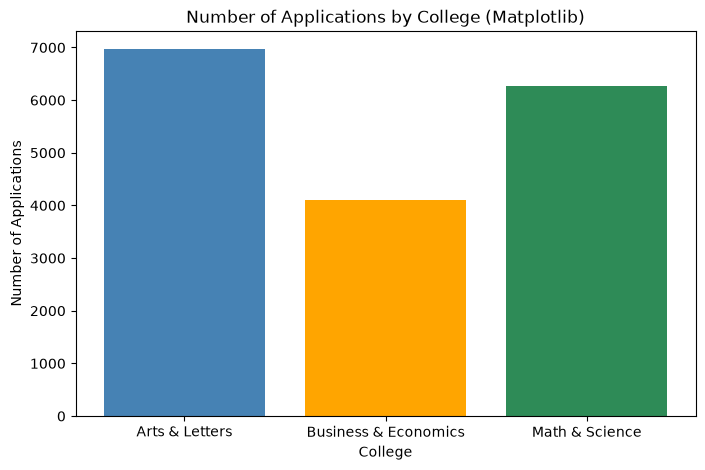

In [32]:
# Matplotlib bar chart: one bar per college, bar height = number of applications
plt.figure(figsize=(8, 5))  # setting the chart size (width, height)
plt.bar(college_counts.index, college_counts.values, color=['steelblue', 'orange', 'seagreen'])
plt.title('Number of Applications by College (Matplotlib)')   # add a title and axis labels
plt.xlabel('College')
plt.ylabel('Number of Applications')
plt.show()

### 1b. Seaborn

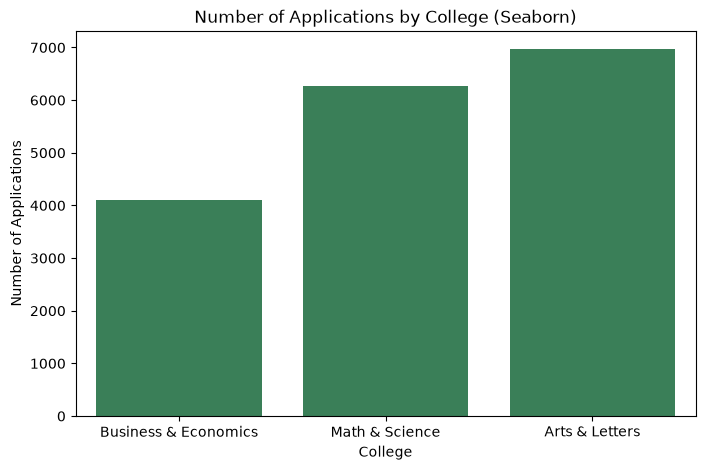

In [33]:
# Seaborn countplot counts the applicants for each college by itself, so I dont think groupby is needed
plt.figure(figsize=(8, 5))  # set the chart size (width, height)
sns.countplot(data=df, x='College', color='seagreen')
plt.title('Number of Applications by College (Seaborn)')
plt.xlabel('College')
plt.ylabel('Number of Applications')
plt.show()

### 1c. Plotly (interactive)

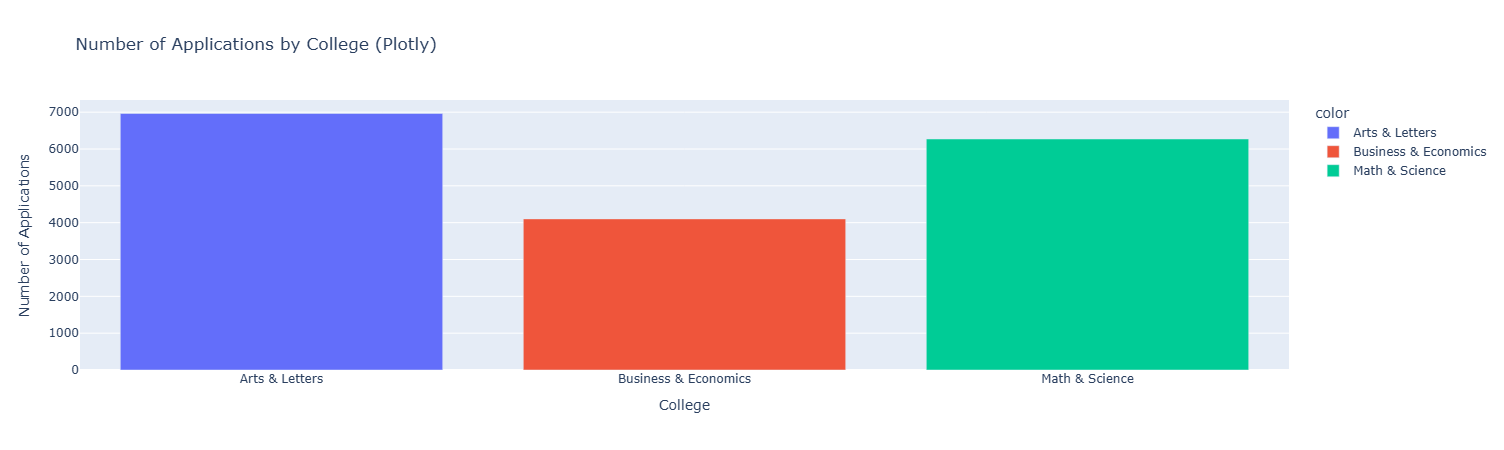

In [34]:
# Plotly bar chart: interactive, so we can hover over a bar to see the exact count
fig = px.bar(x=college_counts.index, y=college_counts.values,
             labels={'x': 'College', 'y': 'Number of Applications'},
             title='Number of Applications by College (Plotly)',
             color=college_counts.index, width=750, height=450)
fig.show()

**Answer:** The college with the tallest bar attracts the most applicants. Arts & Letters attracts the most applicants, with 6,964 of the 17,339 applications (about 40%). Math & Science is second with 6,272 applications (about 36%), and Business & Economics receives the fewest with 4,103 (about 24%). All three charts (Matplotlib, Seaborn, and Plotly) show the same pattern: the Arts & Letters bar is the tallest and the Business & Economics bar is clearly the shortest. Arts & Letters receives about 2,861 more applications than Business & Economics, so demand is not evenly spread across the colleges. This matters for planning because the college with the most applications needs the most review time and admissions staff.

## Task 02: Histogram – Distribution of SAT_ACT Scores
A histogram groups a numerical variable into ranges to show frequency patterns, spread, and skewness.

In [35]:
# Basic statistics for the test scores: average, lowest, highest, and middle values
df['SAT_ACT'].describe()

count    17339.000000
mean      1164.581579
std        172.411636
min        280.000000
25%       1050.000000
50%       1170.000000
75%       1280.000000
max       1600.000000
Name: SAT_ACT, dtype: float64

### 2a. Matplotlib

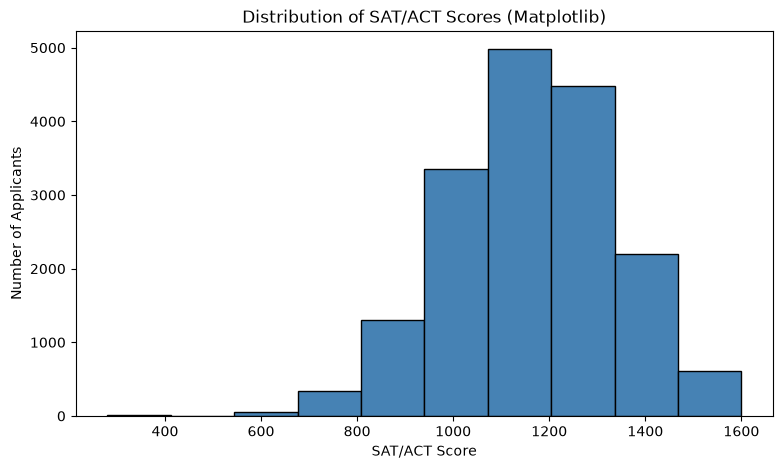

In [36]:
# Matplotlib histogram: splits the scores into 10 ranges and shows how many applicants fall in each section
plt.figure(figsize=(9, 5))
plt.hist(df['SAT_ACT'], bins=10, color='steelblue', edgecolor='black')
plt.title('Distribution of SAT/ACT Scores (Matplotlib)')
plt.xlabel('SAT/ACT Score')
plt.ylabel('Number of Applicants')
plt.show()

### 2b. Seaborn

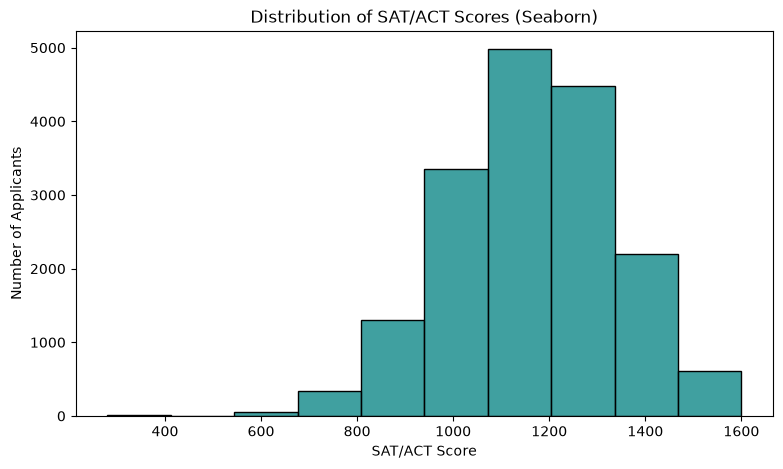

In [37]:
# Seaborn histogram: same idea like matplotlib, with Seaborn's cleaner default style
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='SAT_ACT', bins=10, color='teal')
plt.title('Distribution of SAT/ACT Scores (Seaborn)')
plt.xlabel('SAT/ACT Score')
plt.ylabel('Number of Applicants')
plt.show()

### 2c. Plotly (interactive)

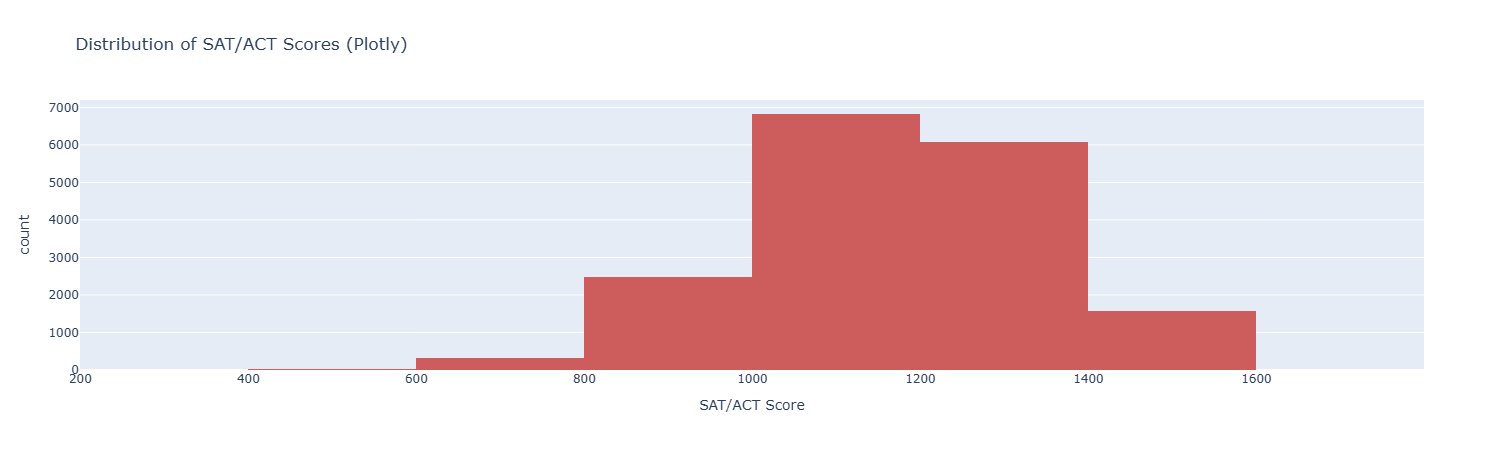

In [38]:
# Plotly histogram: hover over the tallest bar to see the exact score range and count
fig = px.histogram(df, x='SAT_ACT', nbins=10,
                   labels={'SAT_ACT': 'SAT/ACT Score'},
                   title='Distribution of SAT/ACT Scores (Plotly)',
                   color_discrete_sequence=['indianred'], width=800, height=450)
fig.show()

**Reading skewness from the histogram:**
- Bars roughly mirror each other around the peak → **symmetric**
- Longer tail stretching to the right (toward high scores) → **right-skewed (positive)**
- Longer tail stretching to the left (toward low scores) → **left-skewed (negative)**

**Answer:** The most common SAT/ACT score range is the tallest bar in the histogram.
"Most applicants scored between 1000 and 1190."

## Task 03: Scatter Plot – SAT_ACT vs Extracurricular_Hours
A scatter plot shows the relationship between two numerical variables. 
A linear trendline shows the overall direction:
an upward line = positive, a downward line = negative, a flat line = no clear relationship.

### 3a. Matplotlib

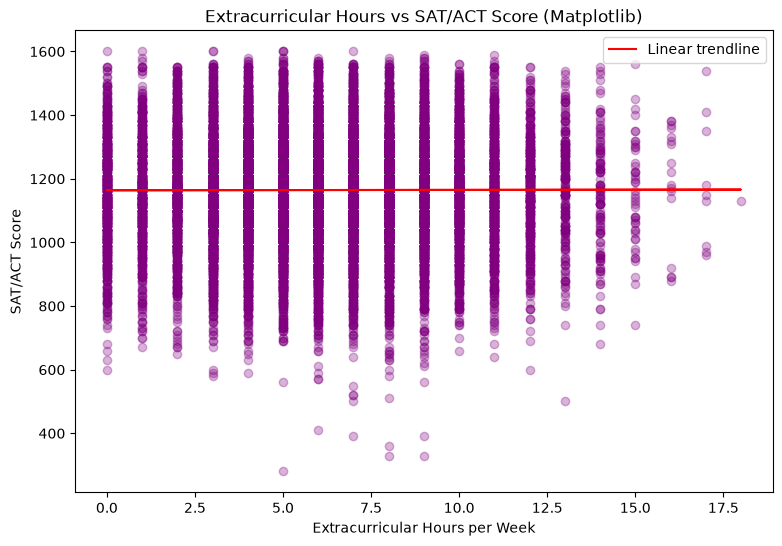

Trendline slope: 0.1066


In [47]:
# Load the tools and the data (needed if the notebook was restarted)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_excel('applications.xlsx')
df = df.dropna()

# Find the straight line that best fits the dots.
# Extracurricular hours is the independent variable (x), SAT/ACT score is the dependent variable (y)
# slope tells us the direction: positive = going up, negative = going down, near 0 = flat
slope, intercept = np.polyfit(df['Extracurricular_Hours'], df['SAT_ACT'], 1)

plt.figure(figsize=(9, 6))
# Each dot is one applicant: weekly extracurricular hours (across) vs test score (up)
plt.scatter(df['Extracurricular_Hours'], df['SAT_ACT'], alpha=0.3, color='purple')
# Draw the trendline in red on top of the dots
plt.plot(df['Extracurricular_Hours'], slope * df['Extracurricular_Hours'] + intercept,
         color='red', label='Linear trendline')
plt.title('Extracurricular Hours vs SAT/ACT Score (Matplotlib)')
plt.xlabel('Extracurricular Hours per Week')
plt.ylabel('SAT/ACT Score')
plt.legend()
plt.show()

print('Trendline slope:', round(slope, 4))

### 3b. Seaborn

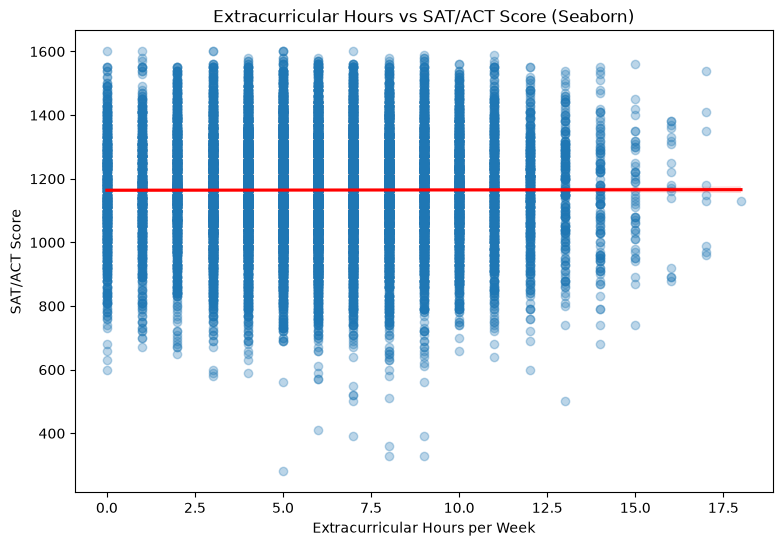

In [48]:
# Seaborn regplot draws the dots AND the trendline in one step
plt.figure(figsize=(9, 6))
sns.regplot(data=df, x='Extracurricular_Hours', y='SAT_ACT',
            scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
plt.title('Extracurricular Hours vs SAT/ACT Score (Seaborn)')
plt.xlabel('Extracurricular Hours per Week')
plt.ylabel('SAT/ACT Score')
plt.show()

### 3c. Plotly (interactive)

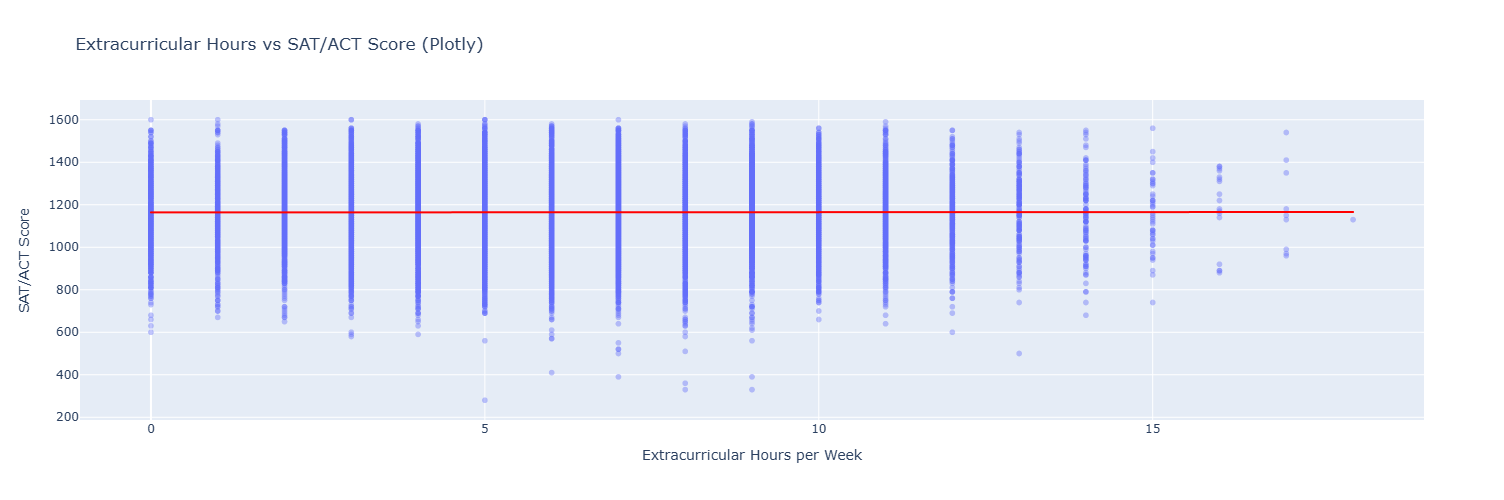

In [49]:
# Plotly scatter plot with a straight trendline added by trendline='ols'
fig = px.scatter(df, x='Extracurricular_Hours', y='SAT_ACT', opacity=0.4,
                 trendline='ols', trendline_color_override='red',
                 labels={'Extracurricular_Hours': 'Extracurricular Hours per Week', 'SAT_ACT': 'SAT/ACT Score'},
                 title='Extracurricular Hours vs SAT/ACT Score (Plotly)', width=850, height=500)
fig.show()

**Answer:** With Extracurricular Hours on the X-axis and SAT/ACT Score on the Y-axis, the points form a wide band at every hour level and the trendline is almost flat (slope = 0.11). This means each extra weekly hour of activities adds only about 0.1 points to the average score, so there is no clear relationship between extracurricular hours and SAT/ACT scores.

## Task 04: Data-Driven Insights
To support the findings, I compare colleges on test scores, admission rate, and enrollment (yield) rate.
- **Admission rate** = admitted ÷ applications
- **Yield rate** = enrolled ÷ admitted

In [42]:
# Turn Yes/No answers into 1/0 so we can add them up
# (Yes = 1, No = 0, so the total of the column = number of Yes answers)
df['Admitted_Code'] = df['Admitted'].map({'Yes': 1, 'No': 0})
df['Enrolled_Code'] = df['Enrolled'].map({'Yes': 1, 'No': 0})
# Show the original and new columns side by side to check the conversion worked
df[['Admitted', 'Admitted_Code', 'Enrolled', 'Enrolled_Code']].head()

,Admitted,Admitted_Code,Enrolled,Enrolled_Code
0,Yes,1,No,0
1,No,0,No,0
2,Yes,1,No,0
3,No,0,No,0
4,No,0,No,0


In [43]:
# Build one summary table with a row for each college:
# number of applications, average test score, average extracurricular hours,
# how many were admitted, and how many enrolled
summary = pd.DataFrame({
    'Applications': df.groupby('College')['Applicant'].count(),
    'Avg_SAT_ACT': df.groupby('College')['SAT_ACT'].mean(),
    'Avg_Extracurricular_Hours': df.groupby('College')['Extracurricular_Hours'].mean(),
    'Admitted': df.groupby('College')['Admitted_Code'].sum(),
    'Enrolled': df.groupby('College')['Enrolled_Code'].sum(),
})
# Admission rate: out of everyone who applied, what percent got in
summary['Admission_Rate_%'] = summary['Admitted'] / summary['Applications'] * 100
# Yield rate: out of everyone who got in, what percent actually enrolled
summary['Yield_Rate_%'] = summary['Enrolled'] / summary['Admitted'] * 100
# Show the table with numbers rounded to 1 decimal place
summary.round(1)

,Applications,Avg_SAT_ACT,Avg_Extracurricular_Hours,Admitted,Enrolled,Admission_Rate_%,Yield_Rate_%
College,,,,,,,
Arts & Letters,6964,1146.4,6.1,1739,541,25.0,31.1
Business & Economics,4103,1173.6,6.1,1470,499,35.8,33.9
Math & Science,6272,1178.9,6.1,2114,488,33.7,23.1


In [44]:
# The same numbers for the whole university, all colleges combined
print('Applications:', df['Applicant'].count())
print("-----------------------------------")
print('Admitted:', df['Admitted_Code'].sum())
print("-----------------------------------")
print('Enrolled:', df['Enrolled_Code'].sum())
print("-----------------------------------")
print('Overall admission rate (%):', round(df['Admitted_Code'].mean() * 100, 1))
print("-----------------------------------")
print('Overall yield rate (%):', round(df['Enrolled_Code'].sum() / df['Admitted_Code'].sum() * 100, 1))

Applications: 17339
-----------------------------------
Admitted: 5323
-----------------------------------
Enrolled: 1528
-----------------------------------
Overall admission rate (%): 30.7
-----------------------------------
Overall yield rate (%): 28.7


In [45]:
# Compare the average test score of students who got in vs students who did not
# A big gap means test scores matter a lot in the admission decision
df.groupby('Admitted')['SAT_ACT'].mean().round(1)

Admitted
No     1110.8
Yes    1286.0
Name: SAT_ACT, dtype: float64

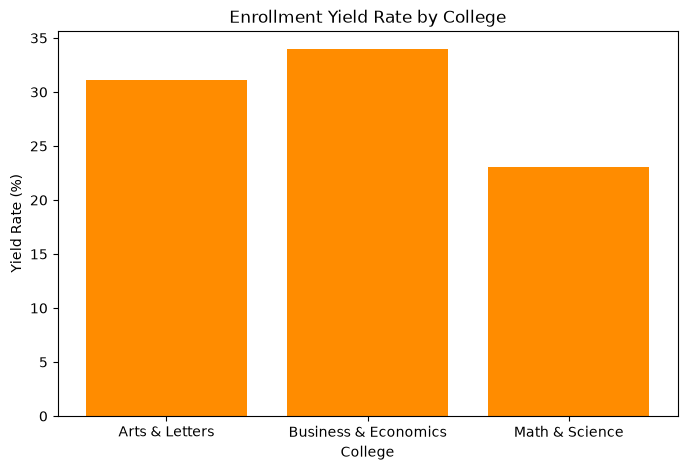

In [46]:
# Bar chart of yield rate by college: shorter bars = colleges losing more admitted students
plt.figure(figsize=(8, 5))
plt.bar(summary.index, summary['Yield_Rate_%'], color='darkorange')
plt.title('Enrollment Yield Rate by College')
plt.xlabel('College')
plt.ylabel('Yield Rate (%)')
plt.show()

### Key Findings

**Finding 1 – Application demand is uneven across colleges.**
Arts & Letters receives the most applications (6,964, about 40% of all 17,339 applications), followed by Math & Science (6,272). Business & Economics receives the fewest (4,103, about 24%). Arts & Letters is also the most selective, admitting only 25.0% of applicants compared with 35.8% in Business & Economics and 33.7% in Math & Science. Admissions staff and review time are under the most pressure in Arts & Letters.

**Finding 2 – SAT/ACT scores cluster in one range, and admission is linked to scores.**
The most common score range is X–Y. Admitted applicants average 1,286.0 compared with 1,110.8 for applicants who were not admitted, a gap of about 175 points. This shows that test scores play a strong role in admission decisions. Average scores are similar across colleges, from 1,146.4 in Arts & Letters to 1,178.9 in Math & Science.

**Finding 3 – Extracurricular hours show no clear relationship with test scores, and yield differs by college.**
The points form a wide cloud and the trendline is almost flat. Every college has the same average of 6.1 extracurricular hours per week. Yield rates range from 33.9% in Business & Economics to 23.1% in Math & Science. Math & Science admits the most students (2,114) but enrolls the fewest (488). Overall, only 1,528 of 5,323 admitted students enrolled (28.7%), so about 7 in 10 admitted students choose not to enroll.

### Recommendations
1. **Match resources to demand.** Assign more reviewers and earlier review deadlines to Arts & Letters, which has the highest application volume and the lowest admission rate. Run targeted recruitment (high-school visits, scholarships, program marketing) for Business & Economics to grow its smaller applicant pool.
2. **Use holistic review.** Extracurricular hours are not tied to test scores, so they show a different side of each applicant. Include them as a separate factor in admission decisions to find strong applicants that scores alone would miss.
3. **Improve yield in Math & Science.** Math & Science loses about 3 out of 4 admitted students. Follow up quickly with admitted students through admitted-student days, faculty and lab outreach, and competitive financial aid offers. Plan class sizes using each college's own yield rate (23.1% to 33.9%) rather than the single university-wide rate of 28.7%.

## Comparing Matplotlib, Seaborn, and Plotly
| Feature | Matplotlib | Seaborn | Plotly |
|---|---|---|---|
| Level | Low-level, full control | High-level, built on Matplotlib | High-level, interactive |
| Syntax | More lines (`plt.bar`, `plt.hist`, `plt.scatter`) | Short, works directly with DataFrames (`countplot`, `histplot`, `regplot`) | Short, DataFrame-based (`px.bar`, `px.histogram`, `px.scatter`) |
| Trendline | Calculated with `np.polyfit`, then drawn with `plt.plot` | Built in with `regplot` | Built in with `trendline='ols'` |
| Interactivity | Static images | Static images | Hover, zoom, pan |
| Best for | Custom, publication-ready charts | Fast statistical charts with good default style | Dashboards and presentations |

## Conclusion
All three libraries showed the same patterns: Matplotlib gives the most control, Seaborn gives quick statistical charts, and Plotly gives interactive charts for stakeholders. The admissions data shows where application demand is concentrated, what score range is typical, how extracurricular hours relate to scores, and where enrollment yield needs attention.

**THANK YOU**